In [1]:
# launch Isaac Sim first (before any other isaaclab import), then build the fixed-parameter cartpole env
# (history-mlp: the same experiments as history.ipynb, but with a Gaussian MLP policy on the concatenated K-step window)
from api import isaac

app = isaac.launch(cameras=True)  # cameras are needed for the video at the end

import math
import time

import torch
import torch.nn as nn
from torch.distributions import Normal

TASK = "Isaac-Cartpole-Direct-v0"
NUM_ENVS = 4096



def side_camera(cfg):
    # camera on env 0 from the side: the rail runs along y, and env 0 sits at the +x corner of the grid, so viewing
    # from +x keeps the other 4095 cartpoles behind it
    cfg.viewer.origin_type = "env"
    cfg.viewer.eye = (5.0, 0.0, 2.5)
    cfg.viewer.lookat = (0.0, 0.0, 2.0)


env = isaac.make_env(TASK, num_envs=NUM_ENVS, render=True, cfg_fn=side_camera)
cfg = env.unwrapped.cfg
device = env.unwrapped.device
max_len = int(cfg.episode_length_s / env.unwrapped.step_dt)
print(f"{TASK}: {NUM_ENVS} envs, obs {cfg.observation_space}, act {cfg.action_space}, episode {max_len} steps")

[INFO][AppLauncher]: Using device: cuda:0
[INFO][AppLauncher]: Loading experience file: /scratch/pranamlab/farazr/control-proj/control/deps/IsaacLab/apps/isaaclab.python.headless.rendering.kit


[Warning] [simulation_app.simulation_app] fast shutdown not supported with jupyter notebooks
Loading user config located at: '/scratch/pranamlab/farazr/control-proj/control/.venv/lib/python3.11/site-packages/isaacsim/kit/data/Kit/Isaac-Sim/5.1/user.config.json'
[Info] [carb] Logging to file: /scratch/pranamlab/farazr/control-proj/control/.venv/lib/python3.11/site-packages/isaacsim/kit/logs/Kit/Isaac-Sim/5.1/kit_20261011_020028.log
2026-10-11T06:00:28Z s] [Warning] [carb.windowing-glfw.plugin] GLFW initialization failed.
2026-10-11T06:00:28Z s] [Warning] [carb] Failed to startup plugin carb.windowing-glfw.plugin (interfaces: [carb::windowing::IGLContext v1.0],[carb::windowing::IWindowing v1.5]) (impl: carb.windowing-glfw.plugin)
2026-10-11T06:00:28Z s] [Warning] [omni.platforminfo.plugin] failed to open the default display.  Can't verify X Server version.
2026-10-11T06:00:28Z s] [Warning] [carb.cudainterop.plugin] CUDA_VISIBLE_DEVICES environment variable is set.
2026-10-11T06:00:28Z s]

[INFO]: Parsing configuration from: isaaclab_tasks.direct.cartpole.cartpole_env:CartpoleEnvCfg
2026-10-11T06:00:29Z [1,228ms] [Warning] [gpu.foundation.plugin] Detected IOMMU is enabled. Running CUDA peer-to-peer bandwidth and latency validation.
Unidirectional P2P=Enabled Bandwidth (P2P Writes) Matrix (GB/s)
   D\D     0 
     0 3321.60 
P2P=Enabled Latency (P2P Writes) Matrix (us)
   GPU     0 
     0   2.54 

   CPU     0 
     0   3.65 
2026-10-11T06:00:30Z [2,210ms] [Warning] [carb.windowing-glfw.plugin] GLFW initialization failed.
2026-10-11T06:00:30Z [2,210ms] [Warning] [carb] Failed to startup plugin carb.windowing-glfw.plugin (interfaces: [carb::windowing::IGLContext v1.0],[carb::windowing::IWindowing v1.5]) (impl: carb.windowing-glfw.plugin)
2026-10-11T06:00:30Z [2,233ms] [Warning] [carb.windowing-glfw.plugin] GLFW initialization failed.
2026-10-11T06:00:30Z [2,233ms] [Warning] [carb] Failed to startup plugin carb.windowing-glfw.plugin (interfaces: [carb::windowing::IGLContex

[INFO]: Base environment:
	Environment device    : cuda:0
	Environment seed      : None
	Physics step-size     : 0.008333333333333333
	Rendering step-size   : 0.016666666666666666
	Environment step-size : 0.016666666666666666


[INFO]: Time taken for scene creation : 2.080201 seconds
[INFO]: Scene manager:  <class InteractiveScene>
	Number of environments: 4096
	Environment spacing   : 4.0
	Source prim name      : /World/envs/env_0
	Global prim paths     : []
	Replicate physics     : True
[INFO]: Starting the simulation. This may take a few seconds. Please wait...


[INFO]: Time taken for simulation start : 1.669555 seconds
[INFO]: Completed setting up the environment...
Isaac-Cartpole-Direct-v0: 4096 envs, obs 4, act 1, episode 300 steps


In [2]:
# MLP policy over the last K steps, concatenated. Step t contributes x_t = [a_{t-1}, s_t] as raw continuous values (no
# tokenization, no binning): a_{t-1} is the previous action (0 at the start of an episode, i.e. z_0 = [0, s_0]) and s_t is
# Isaac's (pole angle, pole vel, cart pos, cart vel). The policy is the original Gaussian MLP from cartpole_ppo.ipynb,
# just wider, with the flattened window as its input. ctx=1 is the Markovian policy; ctx>1 sees the last ctx steps.
# The critic is the exact MLP critic from cartpole_ppo.ipynb (4 -> 32 -> 32 -> 1 on the current state), so only the
# actor differs from that setup (and from history.ipynb's transformer).
STEP_DIM = 5  # [a_{t-1}, s_t]


class ObsHistory:
    """Per-env sliding window of the last `ctx` step vectors, [N, ctx, 5]. At the start of an episode (`fresh`) the window
    is pre-padded with the first step x_0 = [0, s_0] repeated, so the policy always sees ctx full steps."""

    def __init__(self, n, ctx):
        self.window = torch.zeros(n, ctx, STEP_DIM, device=device)

    def push(self, prev_act, obs, fresh):
        """prev_act [N, 1] (zeros where fresh), obs [N, 4], fresh [N] bool -> window [N, ctx, 5]."""
        x = torch.cat([prev_act, obs], dim=1)[:, None]  # [N, 1, 5]
        slid = torch.cat([self.window[:, 1:], x], dim=1)
        self.window = torch.where(fresh[:, None, None], x.expand_as(slid), slid)
        return self.window


class MLPActorCritic(nn.Module):
    def __init__(self, ctx=1, hidden=(128, 128), obs_dim=4, act_dim=1, critic_hidden=(32, 32), init_std=1.0):
        super().__init__()
        self.ctx = ctx

        def mlp(d, hs, out_dim):
            layers = []
            for h in hs:
                layers += [nn.Linear(d, h), nn.ELU()]
                d = h
            return nn.Sequential(*layers, nn.Linear(d, out_dim))

        self.actor = mlp(ctx * STEP_DIM, hidden, act_dim)
        self.critic = mlp(obs_dim, critic_hidden, 1)
        self.log_std = nn.Parameter(torch.full((act_dim,), math.log(init_std)))  # state-independent, as in rsl_rl

    def mean_action(self, window):
        """window [B, ctx, 5] -> action mean [B, act_dim]."""
        return self.actor(window.flatten(1))

    def dist(self, window):
        return Normal(self.mean_action(window), self.log_std.exp())

    def value(self, obs):
        """raw continuous state [B, 4] -> value [B]."""
        return self.critic(obs).squeeze(-1)


SEED = 0  # torch seed for the init; Isaac's sim noise is not seeded, so reruns of training are not bit-identical
ARCH = dict(ctx=1, hidden=(128, 128))  # the original actor was (32, 32); ctx=1 is the Markovian policy
CTX = ARCH["ctx"]
torch.manual_seed(SEED)
ac = MLPActorCritic(**ARCH).to(device)
print(f"{sum(p.numel() for p in ac.parameters()):,} parameters")

18,659 parameters


In [3]:
# PPO with a Gaussian policy: the hyperparameters of isaac-lab-quickstart/cartpole_ppo.ipynb (Isaac Lab's reference)
STEPS_PER_ENV = 16      # rollout length; batch = 16 * 4096 = 65536 transitions
ITERATIONS = 150
EPOCHS = 5
MINIBATCHES = 4
GAMMA, LAM = 0.99, 0.95
CLIP = 0.2
VALUE_COEF, ENTROPY_COEF = 1.0, 0.005
MAX_GRAD_NORM = 1.0
LR, DESIRED_KL = 1e-3, 0.01  # adaptive lr in [1e-5, 1e-2]: shrink/grow lr to keep KL near DESIRED_KL
LR_INIT = LR  # ppo_update adapts the global LR; this is what a training run starts from

opt = torch.optim.Adam(ac.parameters(), lr=LR)


def gae(rewards, values, dones, last_value):
    """Generalized advantage estimation over a [T, N] rollout."""
    adv = torch.zeros_like(rewards)
    next_adv, next_value = 0.0, last_value
    for t in reversed(range(rewards.shape[0])):
        not_done = 1.0 - dones[t]
        delta = rewards[t] + GAMMA * not_done * next_value - values[t]
        next_adv = delta + GAMMA * LAM * not_done * next_adv
        adv[t] = next_adv
        next_value = values[t]
    return adv, adv + values


def ppo_update(model, opt, win, obs, actions, old_logp, old_values, adv, returns):
    global LR
    n = win.shape[0]
    stats = []
    for _ in range(EPOCHS):
        for idx in torch.randperm(n, device=device).chunk(MINIBATCHES):
            d = model.dist(win[idx])
            logp = d.log_prob(actions[idx]).sum(-1)
            v = model.value(obs[idx])
            a = adv[idx]
            a = (a - a.mean()) / (a.std() + 1e-8)

            # clipped surrogate objective
            ratio = torch.exp(logp - old_logp[idx])
            policy_loss = -torch.min(ratio * a, ratio.clamp(1 - CLIP, 1 + CLIP) * a).mean()

            # clipped value loss
            v_clipped = old_values[idx] + (v - old_values[idx]).clamp(-CLIP, CLIP)
            value_loss = torch.max((v - returns[idx]) ** 2, (v_clipped - returns[idx]) ** 2).mean()

            entropy = d.entropy().sum(-1).mean()
            loss = policy_loss + VALUE_COEF * value_loss - ENTROPY_COEF * entropy

            # adaptive learning rate from approximate KL(old || new)
            with torch.no_grad():
                kl = ((ratio - 1) - torch.log(ratio)).mean().item()
            if kl > 2 * DESIRED_KL:
                LR = max(LR / 1.5, 1e-5)
            elif kl < DESIRED_KL / 2:
                LR = min(LR * 1.5, 1e-2)
            for g in opt.param_groups:
                g["lr"] = LR

            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)
            opt.step()
            stats.append((policy_loss.item(), value_loss.item(), entropy.item(), kl))
    return torch.tensor(stats).mean(0).tolist()

In [4]:
# training, cached on disk (utils/experiment_cache.py -> control/data/experiment_cache/): the key hashes everything that
# determines the result, so rerunning this cell with unchanged settings loads the weights instead of retraining.
# Bump TRAIN_VERSION whenever the training code (rollout, PPO update, window, model) changes meaning, since the hash only
# sees these parameters, not the code.
# train() works for any context length K = model.ctx: the policy sees the last K steps (ObsHistory above).
import numpy as np
from utils.experiment_cache import ExperimentCache, pack_state_dict, unpack_state_dict

TRAIN_VERSION = 1
EXPERIMENT = "cartpole_mlp_ppo"
TRAIN_PARAMS = dict(
    version=TRAIN_VERSION, task=TASK, num_envs=NUM_ENVS, seed=SEED, arch=ARCH,
    ppo=dict(steps_per_env=STEPS_PER_ENV, iterations=ITERATIONS, epochs=EPOCHS, minibatches=MINIBATCHES, gamma=GAMMA,
             lam=LAM, clip=CLIP, value_coef=VALUE_COEF, entropy_coef=ENTROPY_COEF, max_grad_norm=MAX_GRAD_NORM,
             lr=LR_INIT, desired_kl=DESIRED_KL),
)


def _sync():
    """Wait for queued GPU work so the per-phase timings below are real."""
    if str(device).startswith("cuda"):
        torch.cuda.synchronize()


def train(model, opt, rand=None, iterations=None):
    """Run PPO on `model` in place; returns the trained weights and training curves as cache arrays.

    rand=None trains on the nominal system. With a CartpoleRandomizer, every env gets a fresh (gain, pole mass, delay)
    draw at each episode start (the envs that just finished are resampled right after the auto-reset).
    `iterations` defaults to ITERATIONS."""
    global LR
    LR = LR_INIT
    iters = ITERATIONS if iterations is None else iterations
    if rand is None and globals().get("rand") is not None:
        globals()["rand"].set(1.0, 1.0, 0)  # a randomizer defined further down may have left randomized parameters
    T, N = STEPS_PER_ENV, NUM_ENVS
    K = model.ctx
    buf_win = torch.zeros(T, N, K, STEP_DIM, device=device)
    buf_obs = torch.zeros(T, N, cfg.observation_space, device=device)
    buf_act = torch.zeros(T, N, cfg.action_space, device=device)
    buf_logp, buf_val, buf_rew, buf_done = (torch.zeros(T, N, device=device) for _ in range(4))

    ep_return = torch.zeros(N, device=device)
    ep_length = torch.zeros(N, device=device)
    history = {"iteration": [], "return": [], "length": [], "steps/s": [], "t_rollout": [], "t_update": []}

    obs = env.reset()[0]["policy"]
    if rand is not None:
        rand.resample()
        rand.reset_buffer()
    prev_act = torch.zeros(N, cfg.action_space, device=device)
    fresh = torch.ones(N, dtype=torch.bool, device=device)
    window = ObsHistory(N, K)
    for it in range(iters):
        t0 = time.time()
        finished_returns, finished_lengths = [], []
        for t in range(T):
            win = window.push(prev_act, obs, fresh)  # [N, K, 5]
            with torch.no_grad():
                d = model.dist(win)
                action = d.sample()
                buf_logp[t] = d.log_prob(action).sum(-1)
                buf_val[t] = model.value(obs)
            buf_win[t], buf_obs[t], buf_act[t] = win, obs, action

            env_action = action if rand is None else rand.apply_action(action)
            next_obs, reward, terminated, truncated, _ = env.step(env_action)
            done = terminated | truncated
            # time-limit truncation is not failure: bootstrap with V(s) (rsl_rl's approximation)
            buf_rew[t] = reward + GAMMA * buf_val[t] * truncated.float()
            buf_done[t] = done.float()

            ep_return += reward
            ep_length += 1
            if done.any():
                finished_returns.append(ep_return[done])
                finished_lengths.append(ep_length[done])
                ep_return[done] = 0
                ep_length[done] = 0
            obs = next_obs["policy"]
            if rand is not None and done.any():
                rand.resample(done.nonzero().squeeze(-1))  # the env already reset: new episode, new system
            # the env auto-resets, so obs is already the first state of a new episode there: no previous action
            prev_act = torch.where(done[:, None], torch.zeros_like(action), action)
            fresh = done

        _sync()
        t_roll = time.time() - t0  # sim stepping + policy forward for the rollout steps
        with torch.no_grad():
            adv, returns = gae(buf_rew, buf_val, buf_done, model.value(obs))
        pl, vl, ent, kl = ppo_update(
            model, opt, buf_win.flatten(0, 1), buf_obs.flatten(0, 1), buf_act.flatten(0, 1), buf_logp.flatten(),
            buf_val.flatten(), adv.flatten(), returns.flatten(),
        )
        _sync()
        t_upd = time.time() - t0 - t_roll  # GAE + the PPO epochs

        if finished_returns:
            history["iteration"].append(it)
            history["return"].append(torch.cat(finished_returns).mean().item())
            history["length"].append(torch.cat(finished_lengths).mean().item())
            history["steps/s"].append(T * N / (time.time() - t0))
            history["t_rollout"].append(t_roll)
            history["t_update"].append(t_upd)
        if it % 10 == 0 or it == iters - 1:
            r = history["return"][-1] if history["return"] else float("nan")
            print(f"it {it:4d} | return {r:7.2f} | ep len {history['length'][-1] if history['length'] else 0:5.1f} | "
                  f"pi {pl:+.3f} v {vl:.3f} ent {ent:.2f} kl {kl:.4f} lr {LR:.1e} | "
                  f"rollout {t_roll:.2f}s update {t_upd:.2f}s | {T * N / (time.time() - t0):,.0f} steps/s")
    return {**pack_state_dict(model.state_dict(), "ac."), **{f"history.{k}": np.asarray(v) for k, v in history.items()}}


cache = ExperimentCache()
key = cache.make_key(EXPERIMENT, TRAIN_PARAMS)
run = cache.get(key)
if run is None:
    print(f"no cached run {key}: training")
    run = train(ac, opt)
    cache.set(key, run, experiment=EXPERIMENT, params=TRAIN_PARAMS)
else:
    print(f"loaded cached run {key}")
ac.load_state_dict(unpack_state_dict(run, "ac.", device=device))
history = {k[len("history."):]: v.tolist() for k, v in run.items() if k.startswith("history.")}

no cached run 3f803e3a7ab3e9fb: training


it    0 | return   -6.28 | ep len  14.8 | pi +0.002 v 21.284 ent 1.42 kl 0.0214 lr 6.7e-04 | rollout 0.54s update 0.28s | 79,573 steps/s


it   10 | return    7.24 | ep len  30.9 | pi -0.009 v 15.703 ent 1.40 kl 0.0099 lr 3.0e-03 | rollout 0.28s update 0.19s | 141,103 steps/s


it   20 | return   56.77 | ep len  81.1 | pi +0.046 v 28.542 ent 1.27 kl 0.0714 lr 1.0e-05 | rollout 0.30s update 0.19s | 133,412 steps/s


it   30 | return   57.04 | ep len  96.0 | pi +0.000 v 15.902 ent 1.27 kl 0.0060 lr 1.0e-02 | rollout 0.30s update 0.20s | 130,506 steps/s


...

it  110 | return  283.75 | ep len 289.3 | pi +0.005 v 5.492 ent 0.44 kl 0.0026 lr 1.0e-02 | rollout 0.31s update 0.20s | 126,356 steps/s


it  120 | return  295.14 | ep len 299.0 | pi +0.002 v 0.822 ent 0.15 kl 0.0035 lr 1.9e-03 | rollout 0.29s update 0.21s | 130,888 steps/s


it  130 | return  295.50 | ep len 299.0 | pi +0.014 v 0.478 ent -0.07 kl 0.0155 lr 1.3e-03 | rollout 0.29s update 0.19s | 135,697 steps/s


it  140 | return  295.75 | ep len 299.0 | pi +0.018 v 0.293 ent -0.18 kl 0.0297 lr 1.0e-05 | rollout 0.30s update 0.17s | 139,142 steps/s


it  149 | return  296.11 | ep len 299.0 | pi -0.000 v 0.168 ent -0.26 kl 0.0052 lr 1.0e-02 | rollout 0.30s update 0.20s | 133,224 steps/s


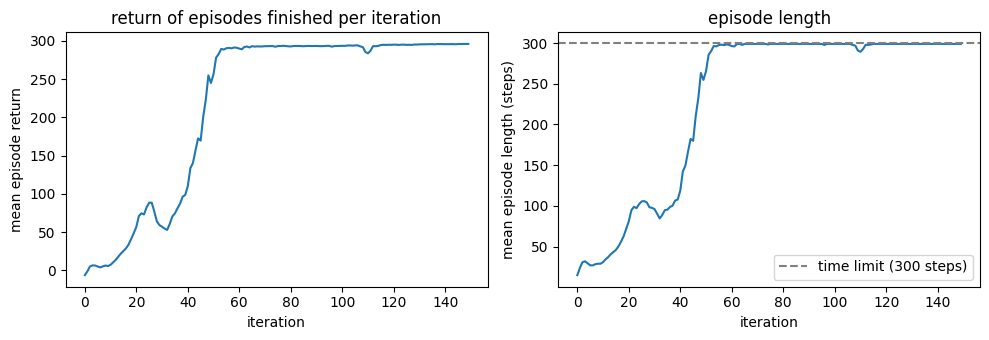

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
axes[0].plot(history["iteration"], history["return"])
axes[0].set(xlabel="iteration", ylabel="mean episode return", title="return of episodes finished per iteration")
axes[1].plot(history["iteration"], history["length"])
axes[1].axhline(max_len, color="gray", ls="--", label=f"time limit ({max_len} steps)")
axes[1].set(xlabel="iteration", ylabel="mean episode length (steps)", title="episode length")
axes[1].legend()
plt.tight_layout()
plt.show()

In [6]:
# deterministic rollout (the policy mean) of the trained policy; video embedded in the notebook (no file on disk)
from api.video import show

obs = env.reset()[0]["policy"]
window = ObsHistory(NUM_ENVS, ac.ctx)
prev_act = torch.zeros(NUM_ENVS, cfg.action_space, device=device)
fresh = torch.ones(NUM_ENVS, dtype=torch.bool, device=device)
frames = []
for _ in range(max_len):
    with torch.no_grad():
        action = ac.mean_action(window.push(prev_act, obs, fresh))
    next_obs, _, terminated, truncated, _ = env.step(action)
    done = terminated | truncated
    obs = next_obs["policy"]
    prev_act = torch.where(done[:, None], torch.zeros_like(action), action)
    fresh = done
    frames.append(env.render())
assert frames[0] is not None and getattr(frames[0], "ndim", 0) == 3, (
    f"env.render() returned {type(frames[0])}; the env must be created with render=True "
    "(isaac.launch(cameras=True) + make_env(render=True)) -- restart the kernel and rerun the setup cell"
)
show(frames, fps=round(1 / env.unwrapped.step_dt))

In [7]:
# domain randomization, resampled per env: actuator gain and pole mass rescaled log-uniformly, plus an action delay
# of 0-3 control steps (1 step = 1/60 s). (api/cartpole_dr.py holds the Isaac physics-view calls; gain 1, mass 1,
# delay 0 is the nominal system the policy trained on.) Pole mass gets a wider range than gain since it barely
# mattered within [0.5, 2].
from api.cartpole_dr import CartpoleRandomizer

rand = CartpoleRandomizer(env, gain_range=(0.5, 2.0), pole_mass_range=(0.2, 5.0), delay_range=(0, 3))
rand.resample()

# sanity checks: the draws cover the ranges, and the engine really applied the masses
print(f"gain      scales: min {rand.gain.min():.2f}  median {rand.gain.median():.2f}  max {rand.gain.max():.2f}")
print(f"pole mass scales: min {rand.pole_mass.min():.2f}  median {rand.pole_mass.median():.2f}  max {rand.pole_mass.max():.2f}")
print("delay (steps) counts:", torch.bincount(rand.delay, minlength=rand.delay_range[1] + 1).tolist())
applied = rand.applied_pole_mass_ratio()
print("max |applied - requested| pole mass ratio:", (applied - rand.pole_mass).abs().max().item())
assert torch.allclose(applied, rand.pole_mass, rtol=1e-3)

gain      scales: min 0.50  median 0.99  max 2.00
pole mass scales: min 0.20  median 1.01  max 4.99
delay (steps) counts: [1035, 1037, 1001, 1023]
max |applied - requested| pole mass ratio: 2.384185791015625e-07


nominal:            return  297.08 | ep len  299.0 / 300
random draw/env:    return  262.40 | ep len  272.3 / 300 | 88.7% survive the full episode


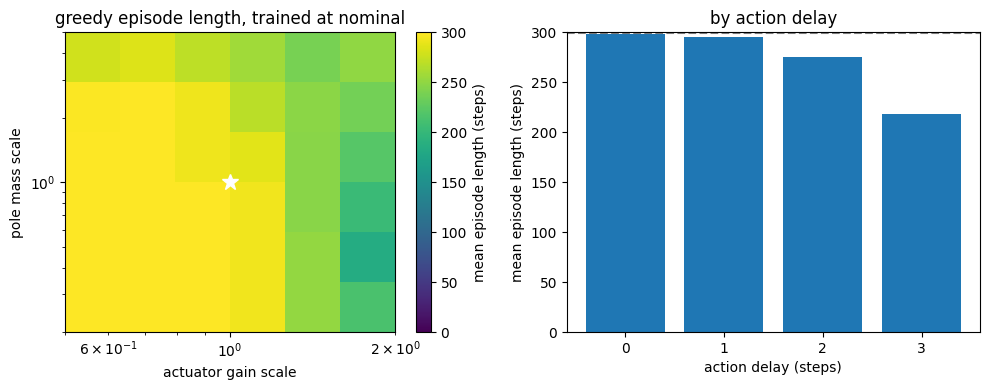

In [8]:
# out-of-domain eval of the policy trained above (it only ever saw the nominal system): one greedy episode per env,
# first on the nominal system, then on an independent random draw per env
import matplotlib.pyplot as plt
import numpy as np


def eval_policy(model):
    """One greedy (policy mean) episode per env under the current rand parameters -> (return [N], length [N]) numpy.
    Reused by every evaluation below, for any context length."""
    obs = env.reset()[0]["policy"]
    rand.reset_buffer()  # delayed actions restart from zero force
    window = ObsHistory(NUM_ENVS, model.ctx)
    prev_act = torch.zeros(NUM_ENVS, cfg.action_space, device=device)
    fresh = torch.ones(NUM_ENVS, dtype=torch.bool, device=device)
    alive = torch.ones(NUM_ENVS, dtype=torch.bool, device=device)
    ret = torch.zeros(NUM_ENVS, device=device)
    length = torch.zeros(NUM_ENVS, device=device)
    for _ in range(max_len):
        with torch.no_grad():
            action = model.mean_action(window.push(prev_act, obs, fresh))
        next_obs, reward, terminated, truncated, _ = env.step(rand.apply_action(action))
        ret += reward * alive
        length += alive
        done = terminated | truncated
        alive &= ~done  # the env auto-resets on done; only the first episode counts
        obs = next_obs["policy"]
        prev_act = torch.where(done[:, None], torch.zeros_like(action), action)
        fresh = done
    return ret.cpu().numpy(), length.cpu().numpy()


rand.set(1.0, 1.0, 0)
nom_ret, nom_len = eval_policy(ac)

rand.resample()
gain, pole_mass, delay = rand.gain.clone(), rand.pole_mass.clone(), rand.delay.clone()
ood_ret, ood_len = eval_policy(ac)
print(f"nominal:            return {nom_ret.mean():7.2f} | ep len {nom_len.mean():6.1f} / {max_len}")
print(f"random draw/env:    return {ood_ret.mean():7.2f} | ep len {ood_len.mean():6.1f} / {max_len} "
      f"| {(ood_len >= max_len - 1).mean():.1%} survive the full episode")

# mean episode length over (gain, pole mass) (left; averaged over delays) and per delay (right)
g_edges = np.geomspace(*rand.gain_range, 7)
m_edges = np.geomspace(*rand.pole_mass_range, 7)
g, m, d_np = gain.cpu().numpy(), pole_mass.cpu().numpy(), delay.cpu().numpy()
sums, _, _ = np.histogram2d(g, m, bins=[g_edges, m_edges], weights=ood_len)
counts, _, _ = np.histogram2d(g, m, bins=[g_edges, m_edges])
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 4))
im = ax.pcolormesh(g_edges, m_edges, (sums / np.maximum(counts, 1)).T, vmin=0, vmax=max_len)
ax.set(xscale="log", yscale="log", xlabel="actuator gain scale", ylabel="pole mass scale",
       title="greedy episode length, trained at nominal")
ax.plot(1.0, 1.0, "w*", ms=12)
fig.colorbar(im, ax=ax, label="mean episode length (steps)")
delays = np.arange(rand.delay_range[0], rand.delay_range[1] + 1)
ax2.bar(delays, [ood_len[d_np == d].mean() for d in delays])
ax2.axhline(max_len - 1, color="gray", ls="--")
ax2.set(xlabel="action delay (steps)", ylabel="mean episode length (steps)", xticks=delays, ylim=(0, max_len),
        title="by action delay")
plt.tight_layout()
plt.show()

In [9]:
# caching for evaluation rollouts and videos, in the same on-disk cache as training (utils/experiment_cache.py).
# Evaluation results are keyed by the policy's weights digest, the system it ran on, and the settings below; videos are
# cached as encoded mp4 bytes (a few hundred KB; the raw frames would be hundreds of MB).
# A cache hit replays a FROZEN result: the env's random initial pole angles (and, for videos, the background envs) are
# not re-drawn, and the key cannot see code. Bump EVAL_VERSION when the eval/render code or camera changes meaning.
import hashlib

from api.video import encode_mp4, video_from_bytes

EVAL_VERSION = 1
EVAL_SEED = 0  # seeds the shared random system draw used by the comparison cells


def weights_digest(model):
    """Short hash of a model's weights, so a retrained policy never hits another policy's cached evaluation."""
    h = hashlib.sha256()
    for name, v in sorted(model.state_dict().items()):
        h.update(name.encode())
        h.update(v.detach().cpu().contiguous().numpy().tobytes())
    return h.hexdigest()[:16]


def _eval_context():
    return dict(version=EVAL_VERSION, policy="mlp-gaussian", task=TASK, num_envs=NUM_ENVS, max_len=max_len, seed=EVAL_SEED,
                dr=dict(gain=rand.gain_range, pole_mass=rand.pole_mass_range, delay=rand.delay_range))


def eval_cached(model, system, evaluator):
    """evaluator(model) -> (return [N], length [N]) under `system`, cached. system=None is the shared random draw
    (gain, pole_mass, delay globals, seeded by EVAL_SEED); otherwise a (gain, pole_mass, delay) tuple for every env."""
    params = dict(_eval_context(), weights=weights_digest(model), ctx=model.ctx, system="draw" if system is None else system)
    key = cache.make_key("cartpole_eval", params)
    hit = cache.get(key)
    if hit is None:
        if system is None:
            rand.set(gain, pole_mass, delay)
        else:
            rand.set(*system)
        ret, length = evaluator(model)
        cache.set(key, {"return": ret, "length": length}, experiment="cartpole_eval", params=params)
        return ret, length
    return hit["return"], hit["length"]


def video_cached(params, render, width=640):
    """render() -> (frames, fps, stats); returns (IPython Video, stats array). Only the mp4 and the stats are cached."""
    params = dict(_eval_context(), kind="video", **params)
    key = cache.make_key("cartpole_video", params)
    hit = cache.get(key)
    if hit is None:
        frames, fps, stats = render()
        hit = {"mp4": np.frombuffer(encode_mp4(frames, fps), dtype=np.uint8), "stats": np.asarray(stats, dtype=float)}
        cache.set(key, hit, experiment="cartpole_video", params=params)
    return video_from_bytes(hit["mp4"].tobytes(), width), hit["stats"]

In [10]:
# videos of env 0 under hand-picked (gain, pole mass, delay): nominal, then the two corners that push the system hardest
# (weak actuator + heavy pole, strong actuator + light pole, both at the longest delay). Greedy policy trained at nominal;
# videos embed in the notebook. Cached as mp4 bytes (see the eval-cache cell above); the other envs in the background
# keep whatever random draw was last set, and a cache hit replays that frozen video.
from IPython.display import display

ids0 = torch.tensor([0], device=device)
demo_settings = [
    (1.0, 1.0, 0),
    (rand.gain_range[0], rand.pole_mass_range[1], rand.delay_range[1]),
    (rand.gain_range[1], rand.pole_mass_range[0], rand.delay_range[1]),
]
for g0, m0, d0 in demo_settings:
    def render():
        obs = env.reset()[0]["policy"]
        rand.set(g0, m0, d0, ids0)  # only env 0 changes; it is the one the camera follows
        rand.reset_buffer()
        window = ObsHistory(NUM_ENVS, ac.ctx)
        prev_act = torch.zeros(NUM_ENVS, cfg.action_space, device=device)
        fresh = torch.ones(NUM_ENVS, dtype=torch.bool, device=device)
        frames, steps_alive, alive = [], 0, True
        for _ in range(max_len):
            with torch.no_grad():
                action = ac.mean_action(window.push(prev_act, obs, fresh))
            next_obs, _, terminated, truncated, _ = env.step(rand.apply_action(action))
            done = terminated | truncated
            steps_alive += alive
            alive = alive and not bool(done[0])
            obs = next_obs["policy"]
            prev_act = torch.where(done[:, None], torch.zeros_like(action), action)
            fresh = done
            frames.append(env.render())
        return frames, round(1 / env.unwrapped.step_dt), [[steps_alive]]

    video, stats = video_cached(
        dict(name="nominal-demo", policy=weights_digest(ac), system=(g0, m0, d0)), render, width=640
    )
    print(f"gain x{g0}, pole mass x{m0}, delay {d0}: env 0 lasted {int(stats[0][0])}/{max_len} steps")
    display(video)

gain x1.0, pole mass x1.0, delay 0: env 0 lasted 299/300 steps


gain x0.5, pole mass x5.0, delay 3: env 0 lasted 95/300 steps


gain x2.0, pole mass x0.2, delay 3: env 0 lasted 16/300 steps


In [11]:
# the same training process, but every episode runs on a freshly randomized system (gain, pole mass, action delay from
# the `rand` distribution above). A new Markovian policy `ac_dr`; `ac` stays the nominal-trained one for comparison.
# It still can't identify the parameters (no history), only hedge against them. Cached like the nominal run, keyed
# additionally by the randomization ranges.
DR_EXPERIMENT = "cartpole_mlp_ppo_dr"
DR_PARAMS = dict(
    TRAIN_PARAMS,
    dr=dict(gain=rand.gain_range, pole_mass=rand.pole_mass_range, delay=rand.delay_range),
)

torch.manual_seed(SEED)
ac_dr = MLPActorCritic(**ARCH).to(device)
opt_dr = torch.optim.Adam(ac_dr.parameters(), lr=LR_INIT)

key_dr = cache.make_key(DR_EXPERIMENT, DR_PARAMS)
run_dr = cache.get(key_dr)
if run_dr is None:
    print(f"no cached run {key_dr}: training under domain randomization")
    run_dr = train(ac_dr, opt_dr, rand=rand)
    cache.set(key_dr, run_dr, experiment=DR_EXPERIMENT, params=DR_PARAMS)
else:
    print(f"loaded cached run {key_dr}")
ac_dr.load_state_dict(unpack_state_dict(run_dr, "ac.", device=device))
history_dr = {k[len("history."):]: v.tolist() for k, v in run_dr.items() if k.startswith("history.")}

no cached run 250da6a2eddf5be1: training under domain randomization


it    0 | return   -5.98 | ep len  14.6 | pi +0.004 v 21.426 ent 1.42 kl 0.0179 lr 1.5e-03 | rollout 0.28s update 0.20s | 136,784 steps/s


it   10 | return   11.37 | ep len  42.7 | pi -0.004 v 16.984 ent 1.48 kl 0.0055 lr 1.0e-02 | rollout 0.31s update 0.20s | 129,968 steps/s


it   20 | return   55.51 | ep len  82.8 | pi +0.013 v 30.540 ent 1.42 kl 0.0205 lr 7.7e-05 | rollout 0.31s update 0.20s | 130,006 steps/s


it   30 | return  236.60 | ep len 261.3 | pi -0.002 v 27.616 ent 1.22 kl 0.0057 lr 1.3e-03 | rollout 0.31s update 0.20s | 129,672 steps/s


...

it  110 | return  280.39 | ep len 287.5 | pi +0.007 v 7.416 ent -0.15 kl 0.0199 lr 1.0e-05 | rollout 0.30s update 0.20s | 132,171 steps/s


it  120 | return  272.90 | ep len 280.5 | pi +0.004 v 6.263 ent -0.32 kl 0.0051 lr 4.4e-03 | rollout 0.25s update 0.17s | 156,509 steps/s


it  130 | return  282.84 | ep len 288.4 | pi +0.004 v 4.819 ent -0.36 kl 0.0140 lr 2.6e-04 | rollout 0.29s update 0.20s | 134,450 steps/s


it  140 | return  259.80 | ep len 267.1 | pi +0.001 v 9.247 ent -0.43 kl 0.0049 lr 1.0e-02 | rollout 0.30s update 0.19s | 134,999 steps/s


it  149 | return  272.90 | ep len 279.4 | pi +0.007 v 6.379 ent -0.49 kl 0.0733 lr 3.4e-05 | rollout 0.33s update 0.20s | 124,005 steps/s


over the randomized distribution (return, mean +- s.e.m. over envs; full episode = survived to the time limit):
  nominal-trained  return  260.35 +- 1.37 | ep len  270.7 / 300 | 88.1% full episodes
  DR-trained       return  276.06 +- 1.10 | ep len  281.0 / 300 | 91.9% full episodes
  DR - nominal return: +15.71 +- 1.73



return at the corners (every env set to the same system):
  setting               nominal-trained           DR-trained
  nominal                297.09 +- 0.03       296.39 +- 0.04
  g0.5/m0.2/d0           296.73 +- 0.03       268.56 +- 1.12
  g0.5/m0.2/d3           293.62 +- 0.04       241.24 +- 1.62
  g0.5/m5.0/d0           273.33 +- 1.06       123.45 +- 2.05
  g0.5/m5.0/d3           189.58 +- 2.03        59.49 +- 1.45
  g2.0/m0.2/d0           289.52 +- 0.51       297.11 +- 0.03
  g2.0/m0.2/d3            10.06 +- 0.17       176.92 +- 1.90
  g2.0/m5.0/d0           296.99 +- 0.03       296.16 +- 0.05
  g2.0/m5.0/d3            15.78 +- 0.21       203.95 +- 2.08


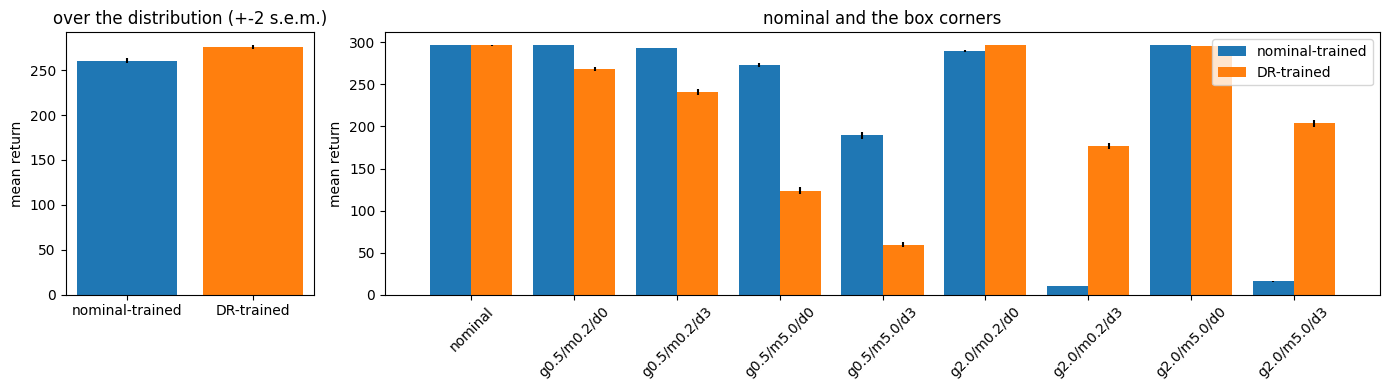

In [12]:
# compare the DR-trained policy `ac_dr` with the nominal-trained `ac` on the distribution of systems: greedy episodes,
# mean first-episode return as the headline number (paired on the same parameter draws), then the extreme corners of
# the randomization box. Initial pole angles are still random per episode, so paired envs differ in their start state.
import itertools

import matplotlib.pyplot as plt
import numpy as np

POLICIES = {"nominal-trained": ac, "DR-trained": ac_dr}


def mean_se(x):
    return x.mean(), x.std(ddof=1) / np.sqrt(len(x))


# 1) the distribution: one draw of NUM_ENVS systems, shared by both policies
torch.manual_seed(EVAL_SEED)  # the shared draw must be reproducible for the eval cache to hit
gain, pole_mass, delay = rand.sample(NUM_ENVS)
dist = {}
for name, model in POLICIES.items():
    dist[name] = eval_cached(model, None, eval_policy)
diff = dist["DR-trained"][0] - dist["nominal-trained"][0]
print("over the randomized distribution (return, mean +- s.e.m. over envs; full episode = survived to the time limit):")
for name, (ret, length) in dist.items():
    m, se = mean_se(ret)
    print(f"  {name:16s} return {m:7.2f} +- {se:.2f} | ep len {length.mean():6.1f} / {max_len} "
          f"| {(length >= max_len - 1).mean():.1%} full episodes")
m, se = mean_se(diff)
print(f"  DR - nominal return: {m:+.2f} +- {se:.2f}")

# 2) the corners of the box (every env set to the same system) plus the nominal system
settings = [("nominal", (1.0, 1.0, 0))] + [
    (f"g{g}/m{m_}/d{d}", (g, m_, d))
    for g, m_, d in itertools.product(rand.gain_range, rand.pole_mass_range, rand.delay_range)
]
corner = {name: {} for name, _ in settings}
for name, params in settings:
    for pname, model in POLICIES.items():
        corner[name][pname] = mean_se(eval_cached(model, params, eval_policy)[0])
print("\nreturn at the corners (every env set to the same system):")
print(f"  {'setting':16s} " + " ".join(f"{p:>20s}" for p in POLICIES))
for name, _ in settings:
    print(f"  {name:16s} " + " ".join(f"{corner[name][p][0]:12.2f} +- {corner[name][p][1]:4.2f}" for p in POLICIES))

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [1, 4]})
colors = ["tab:blue", "tab:orange"]
means = [mean_se(dist[p][0]) for p in POLICIES]
ax.bar(list(POLICIES), [mm for mm, _ in means], yerr=[2 * s for _, s in means], color=colors)
ax.set(ylabel="mean return", title="over the distribution (+-2 s.e.m.)")
x = np.arange(len(settings))
for k, (pname, color) in enumerate(zip(POLICIES, colors)):
    ax2.bar(x + (k - 0.5) * 0.4, [corner[n][pname][0] for n, _ in settings], 0.4,
            yerr=[2 * corner[n][pname][1] for n, _ in settings], color=color, label=pname)
ax2.set(xticks=x, xticklabels=[n for n, _ in settings], ylabel="mean return", title="nominal and the box corners")
ax2.tick_params(axis="x", rotation=45)
ax2.legend()
plt.tight_layout()
plt.show()

In [13]:
# trajectories: nominal-trained (left) vs DR-trained (right) on the same system, side by side. Every env is set to the same
# system so the background matches the foreground. Shown: nominal, then the corner that is worst for each policy.
# The two rollouts start from different random pole angles. Greedy actions; videos embed in the notebook. Cached as mp4
# bytes (see the eval-cache cell above): a hit replays the stored video.
import cv2
from IPython.display import display

corner_names = [n for n, _ in settings if n != "nominal"]
worst = {p: min(corner_names, key=lambda n: corner[n][p][0]) for p in POLICIES}
to_show = list(dict.fromkeys(["nominal", *worst.values()]))  # dedupe, keep order
params_of = dict(settings)


def render_rollout(model, system, label):
    """env 0's greedy episode on `system` (all envs share it) -> (labelled frames, steps survived, return)."""
    rand.set(*system)
    obs = env.reset()[0]["policy"]
    rand.reset_buffer()
    window = ObsHistory(NUM_ENVS, model.ctx)
    prev_act = torch.zeros(NUM_ENVS, cfg.action_space, device=device)
    fresh = torch.ones(NUM_ENVS, dtype=torch.bool, device=device)
    frames, steps, ret, alive = [], 0, 0.0, True
    for _ in range(max_len):
        with torch.no_grad():
            action = model.mean_action(window.push(prev_act, obs, fresh))
        next_obs, reward, terminated, truncated, _ = env.step(rand.apply_action(action))
        done = terminated | truncated
        steps += alive
        ret += float(reward[0]) * alive
        alive = alive and not bool(done[0])
        obs = next_obs["policy"]
        prev_act = torch.where(done[:, None], torch.zeros_like(action), action)
        fresh = done
        frame = np.ascontiguousarray(env.render()).copy()
        cv2.putText(frame, label, (10, 28), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 255, 255), 2, cv2.LINE_AA)
        frames.append(frame)
    return frames, steps, ret


for name in to_show:
    def render():
        runs = {p: render_rollout(model, params_of[name], p) for p, model in POLICIES.items()}
        side_by_side = [np.concatenate([a, b], axis=1) for a, b in zip(*(frames for frames, _, _ in runs.values()))]
        stats = [[steps, ret] for _, steps, ret in runs.values()]
        return side_by_side, round(1 / env.unwrapped.step_dt), stats

    video, stats = video_cached(
        dict(name="side-by-side", policies={p: weights_digest(m) for p, m in POLICIES.items()}, system=params_of[name]),
        render, width=1000,
    )
    print(f"{name} (gain, pole mass, delay) = {params_of[name]}: "
          + " | ".join(f"{p}: {int(steps)}/{max_len} steps, return {ret:.1f}" for p, (steps, ret) in zip(POLICIES, stats)))
    display(video)

nominal (gain, pole mass, delay) = (1.0, 1.0, 0): nominal-trained: 299/300 steps, return 297.1 | DR-trained: 299/300 steps, return 298.6


g2.0/m0.2/d3 (gain, pole mass, delay) = (2.0, 0.2, 3): nominal-trained: 65/300 steps, return 36.1 | DR-trained: 299/300 steps, return 279.6


g0.5/m5.0/d3 (gain, pole mass, delay) = (0.5, 5.0, 3): nominal-trained: 299/300 steps, return 299.0 | DR-trained: 299/300 steps, return 296.2


In [14]:
# long-context policies for in-context system identification: the same DR training, but the policy sees the last K steps
# ([a_{t-1}, s_t] for each, concatenated into the MLP input), K in {2, 5}; a new episode starts with its first step repeated to fill the window.
# K=1 is the Markovian `ac_dr` above. The critic is still the MLP on the current state. Cached per K like the other runs.
CTX_SIZES = (2, 5)
ac_ctx, history_ctx = {}, {}
for K in CTX_SIZES:
    arch = dict(ARCH, ctx=K)
    params = dict(DR_PARAMS, arch=arch)
    torch.manual_seed(SEED)
    model = MLPActorCritic(**arch).to(device)
    opt_k = torch.optim.Adam(model.parameters(), lr=LR_INIT)

    key_k = cache.make_key(DR_EXPERIMENT, params)
    run_k = cache.get(key_k)
    if run_k is None:
        print(f"K={K}: no cached run {key_k}: training ({sum(p.numel() for p in model.parameters()):,} parameters)")
        run_k = train(model, opt_k, rand=rand)
        cache.set(key_k, run_k, experiment=DR_EXPERIMENT, params=params)
    else:
        print(f"K={K}: loaded cached run {key_k}")
    model.load_state_dict(unpack_state_dict(run_k, "ac.", device=device))
    ac_ctx[K] = model
    history_ctx[K] = {k[len("history."):]: v.tolist() for k, v in run_k.items() if k.startswith("history.")}

K=2: no cached run 5ee0dc6373dd1e53: training (19,299 parameters)


it    0 | return   -5.17 | ep len  14.3 | pi +0.002 v 21.714 ent 1.42 kl 0.0193 lr 1.0e-03 | rollout 0.29s update 0.20s | 134,689 steps/s


it   10 | return   11.77 | ep len  39.9 | pi -0.003 v 20.122 ent 1.46 kl 0.0071 lr 1.0e-02 | rollout 0.29s update 0.19s | 136,770 steps/s


it   20 | return   98.38 | ep len 112.8 | pi +0.002 v 25.825 ent 1.22 kl 0.0062 lr 1.0e-02 | rollout 0.33s update 0.20s | 125,897 steps/s


it   30 | return  134.92 | ep len 146.8 | pi -0.000 v 20.503 ent 0.97 kl 0.0024 lr 1.0e-02 | rollout 0.33s update 0.20s | 125,734 steps/s


...

it  110 | return  280.53 | ep len 286.2 | pi -0.000 v 3.800 ent 0.01 kl 0.0069 lr 8.6e-04 | rollout 0.33s update 0.20s | 124,874 steps/s


it  120 | return  288.43 | ep len 294.1 | pi +0.003 v 3.437 ent -0.15 kl 0.0047 lr 1.0e-02 | rollout 0.30s update 0.19s | 132,302 steps/s


it  130 | return  272.36 | ep len 279.8 | pi +0.001 v 5.246 ent -0.16 kl 0.0025 lr 1.0e-02 | rollout 0.29s update 0.17s | 142,936 steps/s


it  140 | return  277.19 | ep len 283.4 | pi +0.001 v 5.081 ent -0.25 kl 0.0031 lr 1.0e-02 | rollout 0.32s update 0.20s | 125,648 steps/s


it  149 | return  277.64 | ep len 284.9 | pi -0.000 v 5.931 ent -0.30 kl 0.0026 lr 1.0e-02 | rollout 0.31s update 0.19s | 132,800 steps/s


over the randomized distribution (return, mean +- s.e.m. over envs):
  nominal K=1        return  260.35 +- 1.37 | ep len  270.7 / 300 | 88.1% full episodes
  DR K=1             return  276.06 +- 1.10 | ep len  281.0 / 300 | 91.9% full episodes
  DR K=2             return  290.30 +- 0.49 | ep len  295.8 / 300 | 98.7% full episodes
  DR K=5             return  284.24 +- 0.84 | ep len  289.5 / 300 | 95.9% full episodes
  DR K=2 - DR K=1 return: +14.25 +- 1.18
  DR K=5 - DR K=1 return: +8.19 +- 1.25

return at the corners (every env set to the same system):
  setting                 nominal K=1               DR K=1               DR K=2               DR K=5
  nominal              297.09 +- 0.03       296.39 +- 0.04       294.81 +- 0.02       296.66 +- 0.04
  g0.5/m0.2/d0         296.73 +- 0.03       268.56 +- 1.12       296.08 +- 0.03       293.71 +- 0.30
  g0.5/m0.2/d3         293.62 +- 0.04       241.24 +- 1.62       295.13 +- 0.05       281.10 +- 0.82
  g0.5/m5.0/d0         273.33 +- 1.

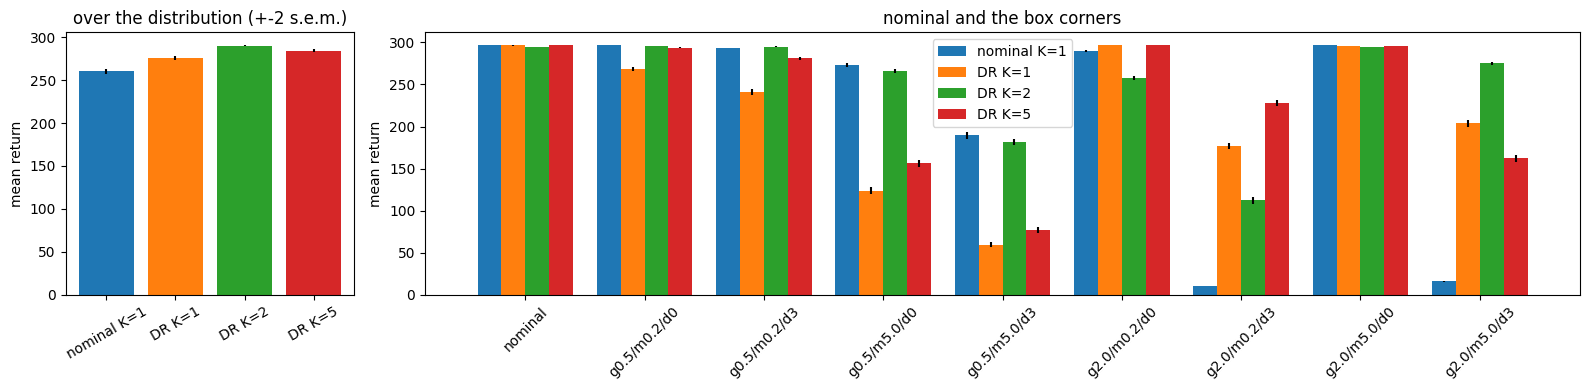

In [15]:
# the same evaluation for the long-context policies, next to the two K=1 policies. Reuses the previous comparison
# cell's results for those (same parameter draw, same corner settings), so run that cell first; only K=2 and K=5 are
# evaluated here. Greedy first-episode returns; four bars: nominal-trained K=1, DR-trained K=1, DR K=2, DR K=5.
# `report_comparison(labels)` prints and plots any set of evaluated policies.
assert all(n in globals() for n in ("dist", "corner", "settings", "gain", "pole_mass", "delay")), (
    "run the nominal-vs-DR comparison cell first"
)
NEW_POLICIES = {f"DR K={K}": ac_ctx[K] for K in CTX_SIZES}
LABELS = ["nominal K=1", "DR K=1", *NEW_POLICIES]


# 1) the distribution: the same NUM_ENVS system draw as the previous comparison
all_dist = {"nominal K=1": dist["nominal-trained"], "DR K=1": dist["DR-trained"]}
for name, model in NEW_POLICIES.items():
    all_dist[name] = eval_cached(model, None, eval_policy)
# 2) the corners (every env set to the same system) plus the nominal system
all_corner = {
    n: {"nominal K=1": corner[n]["nominal-trained"], "DR K=1": corner[n]["DR-trained"]} for n, _ in settings
}
for name, params in settings:
    for pname, model in NEW_POLICIES.items():
        all_corner[name][pname] = mean_se(eval_cached(model, params, eval_policy)[0])


def report_comparison(labels):
    """Print the distribution and corner results for `labels` (keys of all_dist / all_corner) and plot them."""
    print("over the randomized distribution (return, mean +- s.e.m. over envs):")
    for name in labels:
        ret, length = all_dist[name]
        m, se = mean_se(ret)
        print(f"  {name:18s} return {m:7.2f} +- {se:.2f} | ep len {length.mean():6.1f} / {max_len} "
              f"| {(length >= max_len - 1).mean():.1%} full episodes")
    for name in labels:
        if name not in ("nominal K=1", "DR K=1"):
            m, se = mean_se(all_dist[name][0] - all_dist["DR K=1"][0])
            print(f"  {name} - DR K=1 return: {m:+.2f} +- {se:.2f}")

    print("\nreturn at the corners (every env set to the same system):")
    print(f"  {'setting':14s} " + " ".join(f"{p:>20s}" for p in labels))
    for name, _ in settings:
        print(f"  {name:14s} " + " ".join(f"{all_corner[name][p][0]:12.2f} +- {all_corner[name][p][1]:4.2f}" for p in labels))

    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(16, 4), gridspec_kw={"width_ratios": [1, 4]})
    colors = [plt.cm.tab10(k) for k in range(len(labels))]
    means = [mean_se(all_dist[p][0]) for p in labels]
    ax.bar(labels, [mm for mm, _ in means], yerr=[2 * s for _, s in means], color=colors)
    ax.set(ylabel="mean return", title="over the distribution (+-2 s.e.m.)")
    ax.tick_params(axis="x", rotation=30)
    x = np.arange(len(settings))
    w = 0.8 / len(labels)
    for k, (pname, color) in enumerate(zip(labels, colors)):
        ax2.bar(x + (k - (len(labels) - 1) / 2) * w, [all_corner[n][pname][0] for n, _ in settings], w,
                yerr=[2 * all_corner[n][pname][1] for n, _ in settings], color=color, label=pname)
    ax2.set(xticks=x, xticklabels=[n for n, _ in settings], ylabel="mean return", title="nominal and the box corners")
    ax2.tick_params(axis="x", rotation=45)
    ax2.legend()
    plt.tight_layout()
    plt.show()


report_comparison(LABELS)

no cached run b85749955a1de046: training K=5 from scratch for 300 iterations


it    0 | return   -5.08 | ep len  14.4 | pi -0.002 v 22.763 ent 1.42 kl 0.0152 lr 1.5e-03 | rollout 0.25s update 0.17s | 156,981 steps/s


it   10 | return   15.03 | ep len  37.9 | pi -0.005 v 22.240 ent 1.39 kl 0.0100 lr 6.7e-03 | rollout 0.32s update 0.16s | 137,135 steps/s


it   20 | return  117.98 | ep len 132.8 | pi +0.000 v 29.197 ent 1.19 kl 0.0037 lr 1.0e-02 | rollout 0.32s update 0.19s | 128,121 steps/s


it   30 | return  134.43 | ep len 146.3 | pi +0.012 v 19.889 ent 0.97 kl 0.0163 lr 4.4e-03 | rollout 0.30s update 0.19s | 134,332 steps/s


...

it  260 | return  283.34 | ep len 291.6 | pi +0.000 v 2.647 ent 0.17 kl 0.0065 lr 1.0e-02 | rollout 0.31s update 0.20s | 129,002 steps/s


it  270 | return  288.16 | ep len 295.3 | pi +0.003 v 1.769 ent 0.17 kl 0.0130 lr 2.0e-03 | rollout 0.32s update 0.20s | 126,826 steps/s


it  280 | return  283.84 | ep len 292.0 | pi +0.002 v 3.688 ent 0.23 kl 0.0063 lr 1.0e-02 | rollout 0.32s update 0.20s | 125,884 steps/s


it  290 | return  276.68 | ep len 285.5 | pi +0.001 v 3.979 ent 0.30 kl 0.0057 lr 1.0e-02 | rollout 0.31s update 0.20s | 127,049 steps/s


it  299 | return  288.74 | ep len 295.7 | pi +0.005 v 2.266 ent 0.34 kl 0.0285 lr 1.0e-05 | rollout 0.32s update 0.21s | 123,961 steps/s


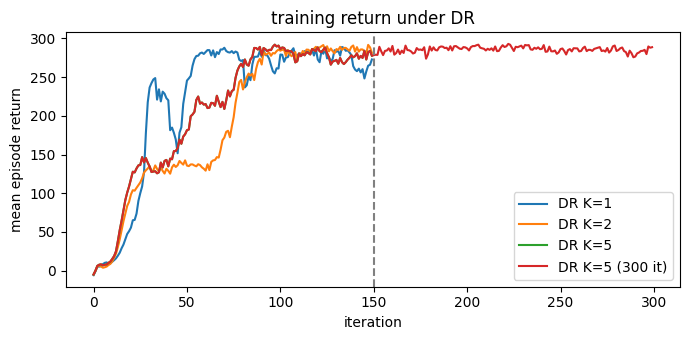

over the randomized distribution (return, mean +- s.e.m. over envs):
  nominal K=1        return  260.35 +- 1.37 | ep len  270.7 / 300 | 88.1% full episodes
  DR K=1             return  276.06 +- 1.10 | ep len  281.0 / 300 | 91.9% full episodes
  DR K=2             return  290.30 +- 0.49 | ep len  295.8 / 300 | 98.7% full episodes
  DR K=5             return  284.24 +- 0.84 | ep len  289.5 / 300 | 95.9% full episodes
  DR K=5 (300 it)    return  288.39 +- 0.59 | ep len  292.4 / 300 | 96.0% full episodes
  DR K=2 - DR K=1 return: +14.25 +- 1.18
  DR K=5 - DR K=1 return: +8.19 +- 1.25
  DR K=5 (300 it) - DR K=1 return: +12.33 +- 1.20

return at the corners (every env set to the same system):
  setting                 nominal K=1               DR K=1               DR K=2               DR K=5      DR K=5 (300 it)
  nominal              297.09 +- 0.03       296.39 +- 0.04       294.81 +- 0.02       296.66 +- 0.04       296.32 +- 0.03
  g0.5/m0.2/d0         296.73 +- 0.03       268.56 +- 1.1

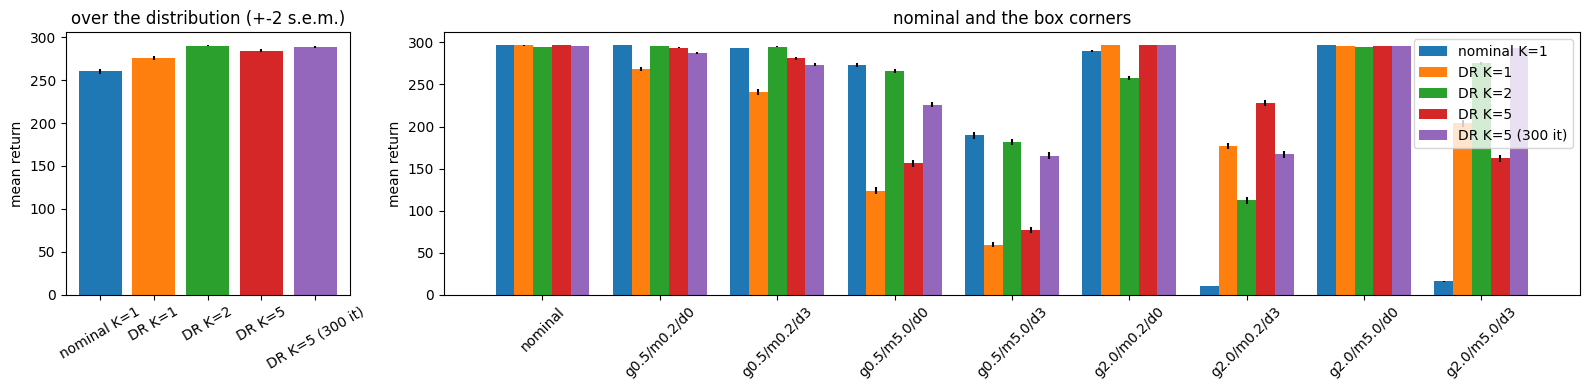

In [16]:
# test whether K=5 is undertrained: train a fresh K=5 policy for LONG_ITERS iterations (twice the ITERATIONS above, same
# seed and settings otherwise) and add it as a fifth policy, evaluated on the same system draw and corner settings as the
# others. Cached under its own key (the iteration count is part of the key).
assert "report_comparison" in globals(), "run the four-policy evaluation cell first"
LONG_ITERS = 2 * ITERATIONS
LONG = f"DR K=5 ({LONG_ITERS} it)"
arch5 = dict(ARCH, ctx=5)
params_long = dict(DR_PARAMS, arch=arch5, ppo=dict(DR_PARAMS["ppo"], iterations=LONG_ITERS))

torch.manual_seed(SEED)
ac_long = MLPActorCritic(**arch5).to(device)
opt_long = torch.optim.Adam(ac_long.parameters(), lr=LR_INIT)
key_long = cache.make_key(DR_EXPERIMENT, params_long)
run_long = cache.get(key_long)
if run_long is None:
    print(f"no cached run {key_long}: training K=5 from scratch for {LONG_ITERS} iterations")
    run_long = train(ac_long, opt_long, rand=rand, iterations=LONG_ITERS)
    cache.set(key_long, run_long, experiment=DR_EXPERIMENT, params=params_long)
else:
    print(f"loaded cached run {key_long}")
ac_long.load_state_dict(unpack_state_dict(run_long, "ac.", device=device))
history_long = {k[len("history."):]: v.tolist() for k, v in run_long.items() if k.startswith("history.")}

# training curves (sampled-action returns on the DR distribution) for context
fig, ax = plt.subplots(figsize=(7, 3.5))
for label, h in [("DR K=1", history_dr), ("DR K=2", history_ctx[2]), ("DR K=5", history_ctx[5]), (LONG, history_long)]:
    ax.plot(h["iteration"], h["return"], label=label)
ax.axvline(ITERATIONS, color="gray", ls="--")  # where the other runs stopped
ax.set(xlabel="iteration", ylabel="mean episode return", title="training return under DR")
ax.legend()
plt.tight_layout()
plt.show()

# evaluate on the same draw and corners as the other policies, then redraw the comparison with five bars
all_dist[LONG] = eval_cached(ac_long, None, eval_policy)
for name, params in settings:
    all_corner[name][LONG] = mean_se(eval_cached(ac_long, params, eval_policy)[0])
report_comparison([*LABELS, LONG])

The fact that the history does not immediately help here is interesting. 

What makes the learning challenge fundamentally harder?